# 01 · Stage 1 — Datafeed

Stage 1 takes a raw source (rows in the source's own vocabulary, with its pedigree scores) and the accounting structure, and returns for every feed a weight matrix $W$ and, on each root edge the feed covers, a value `F_root` with its standard deviation `σ_root`.

> **What this stage assumes**
> - **A2** Every σ composition is one power-mean rule, $p = 1.3$ (Eq. 1); chapter 02 uses the same rule to combine feeds by inverse variance.
> - **A5** No stage before Stage 6 drops σ: a feed leaves Stage 1 as a value and its σ together.
> - **A6** A source edge's outgoing weights in $W$ sum to one; fan-in diversifies, fan-out leaves the CV unchanged.
> - **A7** Pedigree scores map to a CV by the Laner et al. (2016) exponential model, the five indicators summed in quadrature.
> - Copper's choice: a source record that names one endpoint only is fanned across the matching edges by external trade shares, never by a uniform $1/N$ split (ADR 0008; manuscript Table 2). Every row of the toy's feeds names both endpoints, so its $W$ has no fan-out.

In [1]:
import json
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import pandas as pd
from IPython.display import Image, display

from pysuto.acc import AccountingStructure
from pysuto.cases import toy
from pysuto.conc import WeightMatrix
from pysuto.diag import FeedDiagnostics
from pysuto.registry import DataFeedRegistry

RUNS = Path("runs")
PROC = RUNS / "proc"
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

Chapter 00 left the registered inputs in `runs/`. This chapter runs only Stage 1 on top of them: it builds the accounting structure from the registered spec, then turns each of the three sources into one **feed run**.

In [2]:
feed_ids = toy.run_stage1(RUNS)
feed_ids

2026-11-17 09:45:27,207 | AccountingStructure | INFO |   Root: 13 sectors × 3 regions = 39 node definitions | 5 time points | 2 valuations


2026-11-17 09:45:27,208 | AccountingStructure | INFO | RuleSet: 6 supply pairs, 6 use pairs, 1 tradable flows, 5 accounting entity-pair rules


2026-11-17 09:45:27,211 | AccountingStructure | INFO | Total nodes: 39


2026-11-17 09:45:27,212 | AccountingStructure | INFO | Building 2-D node admissibility mask...


2026-11-17 09:45:27,213 | AccountingStructure | INFO | Building 4-D admissibility tensor...


2026-11-17 09:45:27,230 | AccountingStructure | INFO | 
┌─────────────────────────────────────────────────────────┐
│              Edge-space reduction report                │
├─────────────────────────────────────────────────────────┤
│  Theoretical (all node-pairs × T × V) :       15,210  │
│  After node-pair rules                :        1,080  │  (7.1% of theoretical)
│  After all rules (admissible)         :          420  │  (2.8% of theoretical)
│  Reduction from node-pair to final    :          660  │  (61.1% additional removal)
└─────────────────────────────────────────────────────────┘


... (33 outputs left out)

2026-11-17 09:45:27,481 | pysuto.feedpipe | INFO |    run_id        → feed_customs_20261117_094527_83fd40fe


2026-11-17 09:45:27,481 | pysuto.feedpipe | INFO |    run dir       → runs/proc/feed/registry/feed_customs_20261117_094527_83fd40fe


2026-11-17 09:45:27,481 | pysuto.cases.toy | INFO | stage 1: customs → feed_customs_20261117_094527_83fd40fe (15 rows, cv 0.2089)


{'survey': 'feed_survey_20261117_094527_301c0713',
 'bureau': 'feed_bureau_20261117_094527_42f7e139',
 'customs': 'feed_customs_20261117_094527_83fd40fe'}

Three runs, one per source. Each is a directory under `runs/proc/feed/registry/`. The cells below read them back.

In [3]:
acc = AccountingStructure.load("toy", storage_dir=str(PROC / "acc"))
feeds = DataFeedRegistry(odir=str(PROC / "feed" / "registry"))
feeds.load_index()

def load(k):
    e = feeds.resolve(k)
    F = np.load(Path(e.run_dir) / "F_src.npy")
    wm = feeds.load_feed(k, WeightMatrix, acc)
    return SimpleNamespace(id=e.run_id, ct=wm.concordance, W=wm.weight_matrix, F=F, res=feeds.load_result(k))

FEED = {k: load(k) for k in toy.FEED_IDS}

def source_table(k):
    f = FEED[k]; tab = f.ct.tab
    pos = [f.ct.src_edge_to_id[tuple(r)] for r in tab[list(f.ct.SRC_COLS)].itertuples(index=False)]
    return tab.assign(value=f.F[pos])

def edge(fs, fr, ts, tr, t, v):
    q = "from_sector==@fs and from_region==@fr and to_sector==@ts and to_region==@tr and time==@t and valuation==@v"
    return int(acc.edge_meta.query(q)["edge_id"].iloc[0])

2026-11-17 09:45:27,505 | AccountingStructure | INFO | Loading AccountingStructure 'toy' from runs/proc/acc/toy


2026-11-17 09:45:27,507 | AccountingStructure | INFO |    nodes=39  edges=420  time=2001–2005  valuations=['Gross', 'Content']  bound_exceptions=30


2026-11-17 09:45:27,509 | AccountingStructure | INFO |    user masks restored: massbal_scope


## A feed is a list of source edges

Start with the simplest source, the Survey. It publishes ore extraction for the two mining regions, in `kt`, under the heading `crude ore`. Each row is one **source edge**: a flow in the source's own words. The **concordance** translates it into a **root edge**, an edge of the accounting structure. The left half of the table below is the source's vocabulary, the right half the framework's.

In [4]:
VIEW = ["src_sector_from", "src_region_from", "src_time", "src_valuation", "value",
        "root_sector_from", "root_sector_to", "root_region_to", "root_valuation", "weight_value"]
source_table("survey")[VIEW]

,src_sector_from,src_region_from,src_time,src_valuation,value,root_sector_from,root_sector_to,root_region_to,root_valuation,weight_value
0,crude ore,Montara,2001,kt,977.855640,Deposit,Mining,Montara,Gross,1.0
1,crude ore,Montara,2002,kt,805.454225,Deposit,Mining,Montara,Gross,1.0
2,crude ore,Montara,2003,kt,999.920610,Deposit,Mining,Montara,Gross,1.0
3,crude ore,Montara,2004,kt,1145.678153,Deposit,Mining,Montara,Gross,1.0
4,crude ore,Montara,2005,kt,972.389313,Deposit,Mining,Montara,Gross,1.0
5,crude ore,Isla,2001,kt,331.201172,Deposit,Mining,Isla,Gross,1.0
6,crude ore,Isla,2002,kt,431.170208,Deposit,Mining,Isla,Gross,1.0
7,crude ore,Isla,2003,kt,379.770323,Deposit,Mining,Isla,Gross,1.0
8,crude ore,Isla,2004,kt,381.188960,Deposit,Mining,Isla,Gross,1.0
9,crude ore,Isla,2005,kt,343.718648,Deposit,Mining,Isla,Gross,1.0


Ten rows in, ten root edges out, every weight 1: the Survey maps **1:1**. `crude ore` in `kt` becomes `Deposit → Mining` in `Gross`. A feed never changes a value on the way; it only renames it and, where several source edges meet, weighs them.

Every feed run also carries a standard deviation. For Montara's ore in 2003, the Survey's root edge reads:

In [5]:
j = edge("Deposit", "Montara", "Mining", "Montara", "2003", toy.GROSS)
res = FEED["survey"].res
print(f"value {res['F_root'][j]:.1f} kt, σ {res['sigma_root'][j]:.1f} kt, CV {res['cv_root'][j]:.4f}; "
      f"the Survey's CV is {res['cv_src'][0]:.4f}")

value 999.9 kt, σ 104.3 kt, CV 0.1043; the Survey's CV is 0.1043


The root CV equals the Survey's own CV: with one source edge per root edge nothing is combined, so nothing changes. Where does the Survey's CV come from?

## Pedigree → CV

Each source carries five quality scores, from 1 (best) to 4 (worst): its reliability, its completeness, and its temporal, geographical and other correlation to what we want to know. Laner et al. (2016) turn each score into a coefficient of variation (in percent): reliability $0.75\,e^{1.105\,s}$, and each other indicator $0.75\,e^{1.105\,(s-1)}$, which is zero at score 1. The five add in quadrature. The toy gives each source its scores in a sidecar, as a real feed's Excel sheet would.

In [6]:
SCORES = ["reliability", "completeness", "temporal_correlation", "geographical_correlation", "other_correlation"]
meta = {k: feeds.load_metadata(k) for k in toy.FEED_IDS}
scores = pd.DataFrame({k: [getattr(m, a) for a in SCORES] for k, m in meta.items()}, index=SCORES).T
scores

,reliability,completeness,temporal_correlation,geographical_correlation,other_correlation
survey,2,3,2,2,2
bureau,2,1,1,1,1
customs,3,2,1,1,2


In [7]:
def pedigree_cv(s, a=0.75, b=1.105):
    rel = a * np.exp(b * s[0]) / 100
    rest = [a * np.exp(b * (x - 1)) / 100 if x > 1 else 0.0 for x in s[1:]]
    return float(np.sqrt(rel ** 2 + np.sum(np.square(rest))))

scores["CV by hand"] = [pedigree_cv(r) for r in scores.values]
scores["CV in the feed run"] = [FEED[k].res["cv_src"][0] for k in scores.index]
scores.round(4)

,reliability,completeness,temporal_correlation,geographical_correlation,other_correlation,CV by hand,CV in the feed run
survey,2,3,2,2,2,0.1043,0.1043
bureau,2,1,1,1,1,0.0684,0.0684
customs,3,2,1,1,2,0.2089,0.2089


The hand calculation matches the feed run. The Bureau's scores give it the lowest CV and Customs' the highest. The toy's three score sets are copper's own: the Bureau's are those of the ICSG feed, Customs' those of BACI, the Survey's those of crude-ore extraction (manuscript §3.1.3), so the toy's feeds are as noisy as copper's.

One honest sentence on how the toy departs here: its synthetic feeds are drawn at *exactly* the CV their scores imply, so the pedigree is right by construction. For a real feed the scores are a judgement, and chapter 07 asks how good it was.

## The Bureau's fan-in

The Bureau reports refined output as **two series**: primary refineries and secondary refineries. The framework has one edge for it, `Smelting → Metal`. So the two source edges **fan in** to one root edge, and the weight matrix adds them. Here are the Bureau's rows for Portua in 2003, with the root edge each lands on.

In [8]:
bureau = source_table("bureau")
rows = bureau[(bureau["src_region_from"] == "Portua") & (bureau["src_time"] == "2003")]
rows[VIEW[:2] + ["src_sector_to", "src_valuation", "value", "root_sector_from", "root_sector_to", "weight_value"]]

,src_sector_from,src_region_from,src_sector_to,src_valuation,value,root_sector_from,root_sector_to,weight_value
33,primary refinery,Portua,refined,kt orium,6.482056,Smelting,Metal,1.0
34,secondary refinery,Portua,refined,kt orium,2.915348,Smelting,Metal,1.0
53,scrap,Portua,secondary refinery,kt orium,3.075990,Scrap,Smelting,1.0
70,refined,Portua,fabrication,kt orium,8.441720,Metal,Use,1.0
75,refined,Portua,stocks,kt orium,0.092940,Metal,Stock,1.0


Two rows land on `Smelting → Metal`. Look at them as the weight matrix does: the column of $W$ for that root edge has two non-zero entries.

In [9]:
def fan_in(region, year):
    j = edge("Smelting", region, "Metal", region, year, toy.CONTENT)
    f = FEED["bureau"]; w = f.W[:, j].toarray().ravel(); i = np.flatnonzero(w)
    return pd.DataFrame({"value": f.F[i], "weight": w[i]}, index=f.ct.src_edges["src_sector_from"].iloc[i])

fan = fan_in("Portua", "2003")
fan

,value,weight
src_sector_from,,
primary refinery,6.482056,1.0
secondary refinery,2.915348,1.0


The root value is the weighted sum, $\sum_k w_k x_k$. Its σ comes from Eq. (1), the power-mean combiner of the manuscript. Each source edge contributes $w_k\sigma_k$ with $\sigma_k = \mathrm{CV}_{\mathrm{src}}\,|x_k|$, so the root's CV depends only on the **value shares** $\omega_k = |w_k x_k| / \sum_j |w_j x_j|$:

$$\mathrm{CV}_{\mathrm{root}} = \mathrm{CV}_{\mathrm{src}}\Bigl(\sum_k \omega_k^{\,p}\Bigr)^{1/p}, \qquad p = 1.3 .$$

In [10]:
part = (fan["weight"] * fan["value"]).abs()
omega = part / part.sum()
cv_src = float(FEED["bureau"].res["cv_src"][0])
cv_hand = cv_src * (omega ** 1.3).sum() ** (1 / 1.3)
j = edge("Smelting", "Portua", "Metal", "Portua", "2003", toy.CONTENT)
print("value shares ω:", omega.round(3).to_dict())
print(f"CV_src {cv_src:.4f}  →  CV_root by hand {cv_hand:.4f}; in the feed run {FEED['bureau'].res['cv_root'][j]:.4f}")

value shares ω: {'primary refinery': 0.69, 'secondary refinery': 0.31}
CV_src 0.0684  →  CV_root by hand 0.0595; in the feed run 0.0595


The root edge is *more* certain than either series alone. Two independent-looking reports of the same flow tell us more than one. This is the **diversification invariant**: for $p \ge 1$ a power mean of shares is at most 1, so $\mathrm{CV}_{\mathrm{root}} \le \mathrm{CV}_{\mathrm{src}}$ on every root edge. Does it hold across the whole feed, for all three feeds?

In [11]:
def spread(k):
    f = FEED[k]; n = np.asarray((f.W != 0).sum(axis=0)).ravel()
    r = f.res["cv_root"][n > 0] / f.res["cv_src"][0]
    return pd.Series({"root edges covered": (n > 0).sum(), "fed by ≥ 2 source edges": (n > 1).sum(),
                      "min CV_root / CV_src": r.min(), "max CV_root / CV_src": r.max()})

pd.DataFrame({k: spread(k) for k in toy.FEED_IDS}).T.astype(
    {"root edges covered": int, "fed by ≥ 2 source edges": int}).round(3)

,root edges covered,fed by ≥ 2 source edges,min CV_root / CV_src,max CV_root / CV_src
survey,10,0,1.000,1.0
bureau,73,13,0.865,1.0
customs,15,0,1.000,1.0


The ratio never exceeds 1. It is exactly 1 on every edge fed by one source edge, which is all of the Survey's and Customs' edges; only the Bureau's fan-in edges go below. (Fan-*out*, one source edge split over several root edges, would leave the CV unchanged. Copper has it; the toy does not.)

<details><summary>Going deeper: why p = 1.3, and what the weights guarantee</summary>

Eq. (1) is a single rule with one knob. At $p = 2$ it is the textbook Gaussian quadrature of independent errors; at $p = 1$ it is a plain sum, no diversification at all. Copper uses $p = 1.3$, between the two: contributions that meet on one edge rarely err independently, so we grant only part of the Gaussian credit. The next cell evaluates the Portua fan-in at three exponents.

A second guarantee sits in $W$. The outgoing weights of every source edge sum to one, so each fan-out conserves mass, and Stage 1 rejects a projection more than 1 % off the matched raw total. The second cell checks the row sums of all three feeds.
</details>

In [12]:
for p in (1.0, 1.3, 2.0):
    print(f"p = {p}: CV_root = {cv_src * (omega ** p).sum() ** (1 / p):.4f}")

p = 1.0: CV_root = 0.0684
p = 1.3: CV_root = 0.0595
p = 2.0: CV_root = 0.0517


In [13]:
print({k: bool(np.allclose(np.asarray(FEED[k].W.sum(axis=1)).ravel(), 1.0)) for k in toy.FEED_IDS})

{'survey': True, 'bureau': True, 'customs': True}


## The one edge two feeds cover

The Bureau publishes one more table, apart from its content chain: Isla's ore tonnage, in `Gross`. That is `Deposit → Mining` for Isla, an edge the Survey covers too. So after Stage 1 two feeds hold a value and a σ for the same root edge. Stage 1 does not combine them; each feed stays a separate run. Chapter 02 will.

In [14]:
def at(k, t):
    j = edge("Deposit", "Isla", "Mining", "Isla", t, toy.GROSS)
    return pd.Series({"value (kt)": FEED[k].res["F_root"][j], "σ (kt)": FEED[k].res["sigma_root"][j]})

both = pd.concat({k: pd.DataFrame({t: at(k, t) for t in toy.YEARS}).T for k in ("survey", "bureau")}, axis=1)
gap = both[("bureau", "value (kt)")] - both[("survey", "value (kt)")]
both["Bureau vs Survey (% of Survey)"] = 100 * gap / both[("survey", "value (kt)")]
both["gap in combined σ"] = gap / np.hypot(both[("survey", "σ (kt)")], both[("bureau", "σ (kt)")])
both.round(2)

survey            bureau        Bureau vs Survey (% of Survey) gap in combined σ
     value (kt) σ (kt) value (kt) σ (kt)                                                 
2001     331.20  34.56     337.30  23.06                           1.84              0.15
2002     431.17  44.99     424.02  28.99                          -1.66             -0.13
2003     379.77  39.62     417.25  28.53                           9.87              0.77
2004     381.19  39.77     430.50  29.43                          12.94              1.00
2005     343.72  35.86     442.27  30.24                          28.67              2.10

Two reports of one flow, each with its own σ. They disagree by up to about a quarter of the Survey's value, and the largest gap is about two combined σ. Here Stage 1 ends and Stage 2 begins: to weigh the two by their σ.

## The Customs feed and its partner codes

Customs does not say "Montara". It reports bilateral concentrate trade under the codes `101`, `202` and `303`, in `kt`, under the heading `261790`. The concordance carries the map from code to region. Here are the 2001 rows.

In [15]:
customs = source_table("customs")
customs[customs["src_time"] == "2001"][
    ["src_sector_from", "src_region_from", "src_region_to", "value", "root_sector_from",
     "root_region_from", "root_sector_to", "root_region_to", "root_valuation"]]

,src_sector_from,src_region_from,src_region_to,value,root_sector_from,root_region_from,root_sector_to,root_region_to,root_valuation
0,261790,101,202,22.769569,Concentrate,Montara,Smelting,Portua,Gross
5,261790,101,303,3.685727,Concentrate,Montara,Smelting,Isla,Gross
10,261790,303,202,1.628059,Concentrate,Isla,Smelting,Portua,Gross


`101` is Montara, `202` Portua, `303` Isla. Customs records only flows that **cross a border**, so there are three legs a year (Montara to Portua, Montara to Isla, Isla to Portua) and nothing for a region's own concentrate. Each leg maps 1:1 to a `Concentrate → Smelting` edge in `Gross`, and the domestic legs stay uncovered. Stage 2 will have to fill them from somewhere else.

## The diagnostics panel

Every feed run is read with `FeedDiagnostics`: six panels on row coverage, the reasons rows go unmatched, value by process, the distribution of source values, of root CVs, and coverage by year. It wants the raw rows, so we rebuild them from the run's concordance and source values.

   Feed diagnostics → runs/figs/feed_bureau/feed.png  ✓


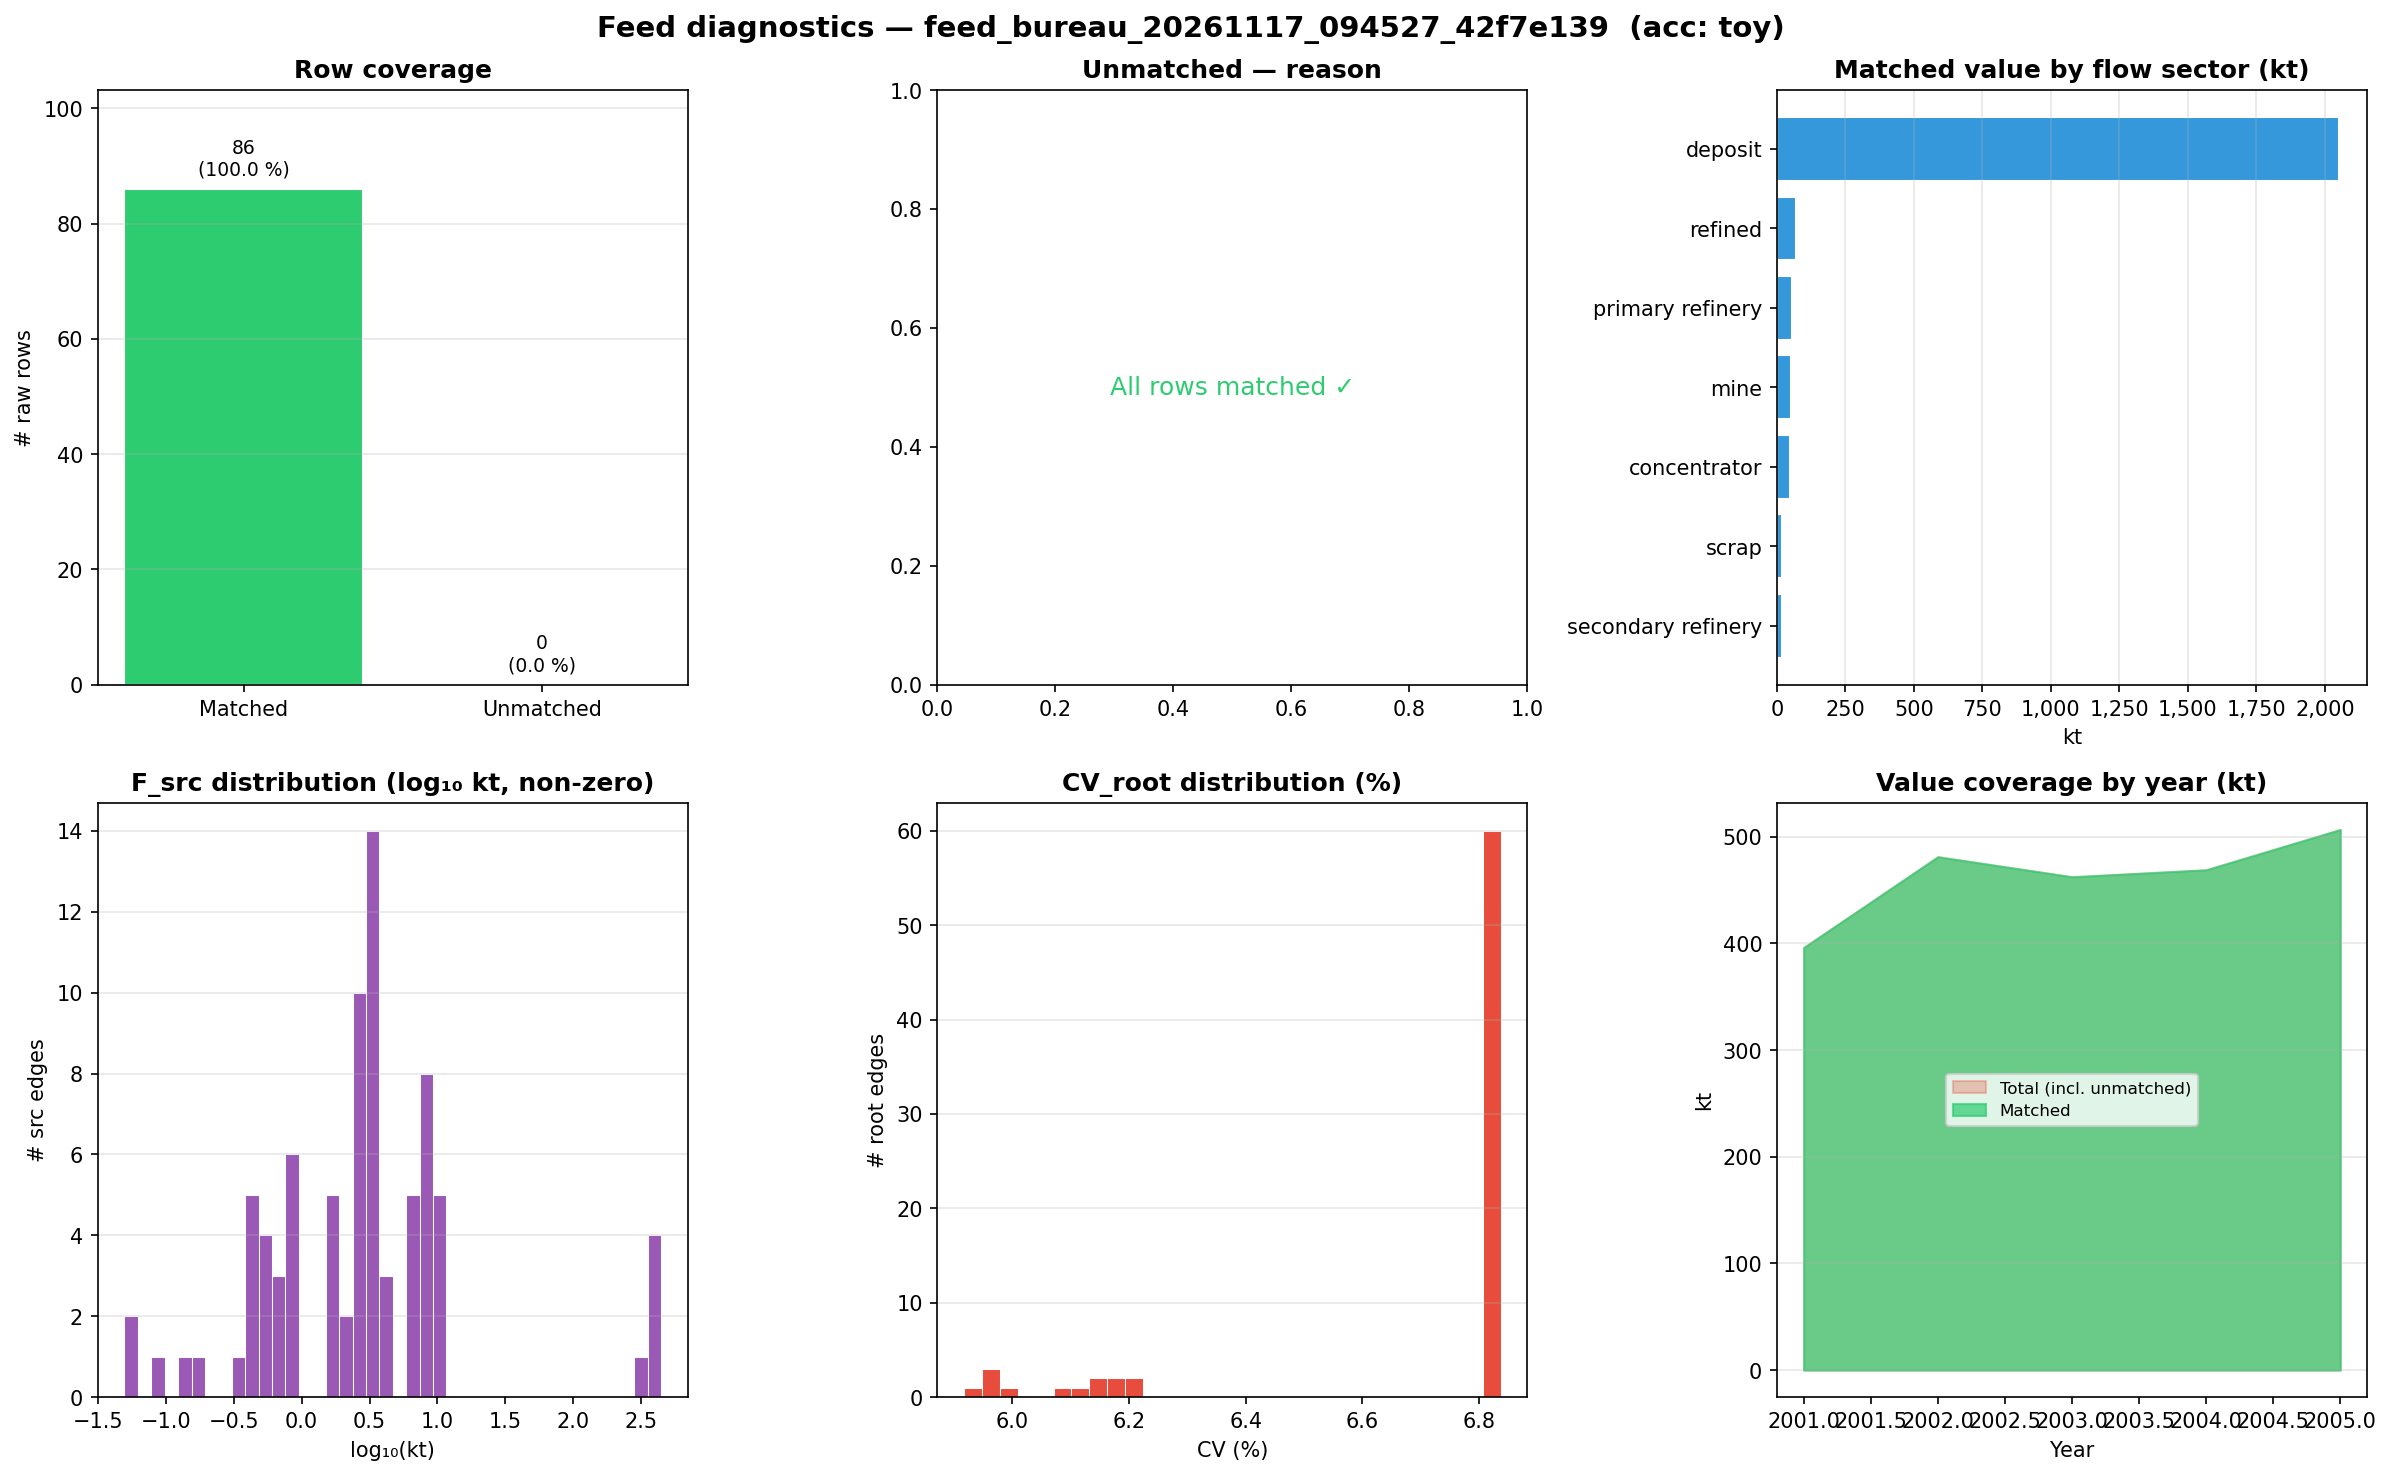

In [16]:
def raw_of(k):
    t = source_table(k)
    return pd.DataFrame({"Year": t["src_time"].values, "Process": t["src_sector_from"].values,
                         "Region": t["src_region_from"].values, "Value": t["value"].values},
                        index=t["raw_id"].values).sort_index()

f = FEED["bureau"]
result = SimpleNamespace(cv_root=f.res["cv_root"], cv_src=float(f.res["cv_src"][0]), F_root=f.res["F_root"])
diag = FeedDiagnostics(f.id, "bureau", "toy", raw_of("bureau"), f.ct, f.F, result)
path = diag.plot(odir=str(RUNS / "figs" / "feed_bureau"))
display(Image(path))

In [17]:
_ = diag.summary()

────────────────────────────────────────────────────────────
  FEED DIAGNOSTICS — feed_bureau_20261117_094527_42f7e139  (acc: toy)
────────────────────────────────────────────────────────────
  Raw rows total  :       86
  Rows matched    :       86  (100.0 %)
  Rows unmatched  :        0  (0.0 %)
  Value matched   :    2,315.1 kt
  Value total     :    2,315.1 kt
  Value coverage  :   100.0 %
  Src edges       :       86
  Root edges      :      420
  CV_src          :   6.84 %
────────────────────────────────────────────────────────────


The panels read like this. All 86 rows matched, so the second panel is empty. The CV panel (bottom middle) shows what the fan-in did: one tall bar at the Bureau's own CV for every edge with a single source, and a short tail below it for the 13 fan-in edges. The Bureau mixes two units (`kt Content` for the chain, `kt` for Isla's ore tonnage), and the panels that add up values add them as they are, so the ore tonnage dominates the process panel; read those two panels for their shape only.

**Exercise 1.1** — Compute the CV of the refined-output edge `Smelting → Metal` of Isla in 2001 by hand, from the two series' values and the Bureau's CV, with Eq. (1) at $p = 1.3$, and check it with `toy.check_1_1`. Cover the next cell and try it first; `toy.solution("1.1")` prints the reference.

In [18]:
fan = fan_in("Isla", "2001")
share = (fan["weight"] * fan["value"]).abs()
omega = share / share.sum()
cv = cv_src * (omega ** 1.3).sum() ** (1 / 1.3)
print(toy.check_1_1(RUNS, cv, "Isla", "2001"))

2026-11-17 09:45:28,395 | AccountingStructure | INFO | Loading AccountingStructure 'toy' from runs/proc/acc/toy


2026-11-17 09:45:28,397 | AccountingStructure | INFO |    nodes=39  edges=420  time=2001–2005  valuations=['Gross', 'Content']  bound_exceptions=30


2026-11-17 09:45:28,398 | AccountingStructure | INFO |    user masks restored: massbal_scope


✓ 1.1  the fan-in CV is 0.0621, below the Bureau's own CV


## Where this run came from

Every feed run writes a sidecar. This one names the accounting-structure entry it read (`parents.inputs`); a feed has no upstream run (`parents.upstream`).

In [19]:
sidecar = json.loads((PROC / "feed" / "registry" / feed_ids["bureau"] / "metadata.json").read_text())
print("parents.inputs  :", sidecar["parents"]["inputs"])
print("parents.upstream:", sidecar["parents"]["upstream"])
print("stage_config    :", sidecar["stage_config"])

parents.inputs  : {'acc': {'id': 'toy', 'version': 1, 'date': '2026-11-17T09:45:24Z', 'code': '2784d5a4', 'label': 'toy'}, 'feed': {'id': 'bureau'}}
parents.upstream: {}
stage_config    : {'p': 1.3, 'seed': 59}


The inputs name version 1 of the registered acc and the feed's own id, the same entry that chapter 00 registered. The sidecar also records the seed of the synthetic feed (`stage_config`). Next: [chapter 02](02_aggregate_impute.ipynb), where three feeds become one prior.